> **Version formatrice.** Tous les exercices sont complétés et le notebook a été exécuté. Les participants utilisent la version à compléter, à la racine du dossier.

# IA101 — Notebook 3 — Évaluer un modèle

**Durée : 20 minutes** · Objectif visé : **O4** — évaluer un modèle avec une métrique adaptée

Une exactitude de 90 % peut être excellente ou insuffisante : tout dépend de la répartition des classes et du **coût des erreurs**. Ce notebook utilise un cas de dépistage du cancer du sein, où manquer un cancer est beaucoup plus grave qu'une fausse alerte.

### Plan
1. Les limites de l'exactitude
2. La régression logistique
3. La matrice de confusion
4. Précision et rappel
5. Le seuil de décision

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

donnees = load_breast_cancer()
X = donnees.data
y = 1 - donnees.target          # recodage : 1 = tumeur maligne (classe positive), 0 = bénigne
print(f"{len(y)} tumeurs, {X.shape[1]} variables")
print(f"Malignes : {y.sum()} ({y.mean():.0%}) | Bénignes : {(1 - y).sum()} ({1 - y.mean():.0%})")

X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

569 tumeurs, 30 variables
Malignes : 212 (37%) | Bénignes : 357 (63%)


## 1. Les limites de l'exactitude

**Prédiction.** Un classifieur trivial prédit toujours la classe majoritaire (« bénin »), sans consulter les variables. Quelle exactitude obtient-il ?

In [3]:
trivial = DummyClassifier(strategy="most_frequent").fit(X_ent, y_ent)
print(f"Exactitude du classifieur trivial : {trivial.score(X_test, y_test):.1%}")
print(f"Tumeurs malignes détectées : {trivial.predict(X_test).sum()} sur {y_test.sum()}")

Exactitude du classifieur trivial : 62.9%
Tumeurs malignes détectées : 0 sur 53


Une exactitude supérieure à 60 % sans détecter **aucune** tumeur maligne. Lorsque les classes sont **déséquilibrées**, l'exactitude seule est trompeuse : il faut analyser le **type** d'erreurs commises.

## 2. La régression logistique

Malgré son nom, la régression logistique est une méthode de **classification**. Elle calcule une combinaison linéaire des variables, $z = w^\top x + b$, puis la transforme en probabilité avec la fonction sigmoïde :

$$P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Ses paramètres $w$ et $b$ sont estimés en minimisant l'**entropie croisée** par une méthode itérative, selon le principe vu au notebook 1. Par défaut, la classe prédite est 1 si la probabilité dépasse **0,5**.

In [4]:
modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele.fit(X_ent, y_ent)
print(f"Exactitude de la régression logistique : {modele.score(X_test, y_test):.1%}")

Exactitude de la régression logistique : 98.6%


## 3. La matrice de confusion

| | **Prédit : bénin** | **Prédit : malin** |
| --- | --- | --- |
| **Réel : bénin** | Vrai négatif (VN) | Faux positif (FP) — fausse alerte |
| **Réel : malin** | Faux négatif (FN) — cancer non détecté | Vrai positif (VP) |

Les deux types d'erreurs n'ont pas le même coût :
- un **faux positif** entraîne des examens complémentaires et de l'inquiétude ;
- un **faux négatif** signifie qu'un cancer n'est pas traité.

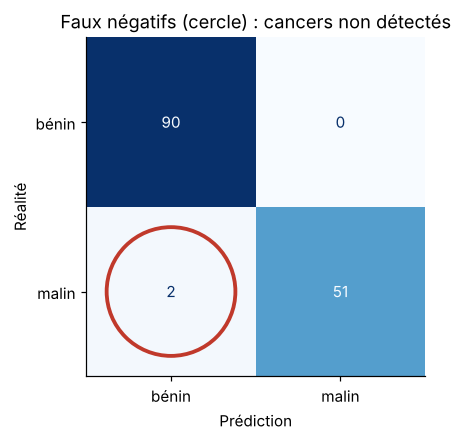

In [5]:
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_estimator(modele, X_test, y_test, display_labels=["bénin", "malin"],
                                      cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
ax.add_patch(plt.Circle((0, 1), 0.38, fill=False, color="#c0392b", lw=2.5))
ax.set_title("Faux négatifs (cercle) : cancers non détectés"); plt.show()

## 4. Précision et rappel

$$\text{Précision} = \frac{VP}{VP + FP} \qquad\qquad \text{Rappel} = \frac{VP}{VP + FN}$$

- **Précision** : parmi les cas signalés positifs, quelle proportion l'est réellement ? (fiabilité des alertes)
- **Rappel** (ou sensibilité) : parmi les cas réellement positifs, quelle proportion est détectée ?

En dépistage, on privilégie généralement un **rappel élevé**.

### Exercice 7 — Calculer la précision et le rappel

**Corrigé**

In [6]:
predictions = modele.predict(X_test)
vn, fp, fn, vp = confusion_matrix(y_test, predictions).ravel()
print(f"VN = {vn}, FP = {fp}, FN = {fn}, VP = {vp}")

precision = vp / (vp + fp)
rappel = vp / (vp + fn)

print(f"Précision : {precision:.1%} (scikit-learn : {precision_score(y_test, predictions):.1%})")
print(f"Rappel    : {rappel:.1%} (scikit-learn : {recall_score(y_test, predictions):.1%})")

VN = 90, FP = 0, FN = 2, VP = 51
Précision : 100.0% (scikit-learn : 100.0%)
Rappel    : 96.2% (scikit-learn : 96.2%)


## 5. Le seuil de décision

Le seuil de 0,5 est une convention. En l'**abaissant**, on signale davantage de cas : moins de cancers manqués, mais plus de fausses alertes.

**Prédiction.** Avec un seuil de 0,2, le rappel augmente-t-il ou diminue-t-il ? Et la précision ?

### Exercice 8 — Modifier le seuil

**Corrigé**

In [7]:
probas = modele.predict_proba(X_test)[:, 1]

seuil = 0.2
predictions_seuil = (probas >= seuil).astype(int)

vn, fp, fn, vp = confusion_matrix(y_test, predictions_seuil).ravel()
print(f"Seuil {seuil} : cancers non détectés = {fn} | fausses alertes = {fp}")
print(f"Précision : {precision_score(y_test, predictions_seuil):.1%} | Rappel : {recall_score(y_test, predictions_seuil):.1%}")

Seuil 0.2 : cancers non détectés = 1 | fausses alertes = 9
Précision : 85.2% | Rappel : 98.1%


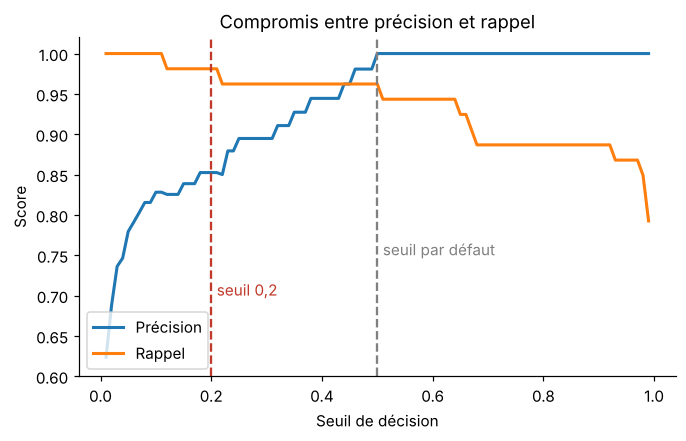

In [8]:
seuils = np.linspace(0.01, 0.99, 99)
precisions = [precision_score(y_test, (probas >= s).astype(int), zero_division=1) for s in seuils]
rappels = [recall_score(y_test, (probas >= s).astype(int)) for s in seuils]

plt.figure(figsize=(7, 4))
plt.plot(seuils, precisions, lw=2, label="Précision")
plt.plot(seuils, rappels, lw=2, label="Rappel")
plt.axvline(0.5, color="gray", ls="--"); plt.text(0.51, 0.75, "seuil par défaut", color="gray")
plt.axvline(0.2, color="#c0392b", ls="--"); plt.text(0.21, 0.70, "seuil 0,2", color="#c0392b")
plt.xlabel("Seuil de décision"); plt.ylabel("Score"); plt.ylim(0.6, 1.02)
plt.title("Compromis entre précision et rappel"); plt.legend(loc="lower left"); plt.show()

**Discussion (2 minutes).** Quel seuil retiendriez-vous pour un outil de dépistage en clinique ? Et pour un filtre de courriels indésirables, où une fausse alerte fait perdre un message important ?

Il n'existe pas de seuil universel. Le choix dépend du **coût relatif des erreurs** et doit être fait avec les experts du domaine.

In [9]:
quiz("Un outil de dépistage doit manquer le moins de cas possible. Quelle métrique faut-il surveiller en priorité ?",
     ["La précision", "Le rappel", "L'exactitude"],
     1, "Le rappel mesure la proportion de cas positifs effectivement détectés.")

**Question de vérification.** Un outil de dépistage doit manquer le moins de cas possible. Quelle métrique faut-il surveiller en priorité ?

RadioButtons(layout=Layout(width='max-content'), options=('La précision', 'Le rappel', "L'exactitude"), value=…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [10]:
quiz("Si l'on abaisse le seuil de décision, en général :",
     ["le rappel augmente et la précision diminue", "le rappel diminue et la précision augmente", "les deux augmentent"],
     0, "Davantage de cas sont signalés : moins de faux négatifs, mais plus de faux positifs.")

**Question de vérification.** Si l'on abaisse le seuil de décision, en général :

RadioButtons(layout=Layout(width='max-content'), options=('le rappel augmente et la précision diminue', 'le ra…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## À retenir

- L'**exactitude** est trompeuse lorsque les classes sont déséquilibrées.
- La **matrice de confusion** distingue faux positifs et faux négatifs.
- **Précision** : fiabilité des alertes. **Rappel** : proportion des cas positifs détectés.
- Le **seuil de décision** arbitre entre les deux, en fonction du coût des erreurs dans le contexte d'utilisation.

**Notebook suivant :** 4 — Améliorer un modèle.